<a href="https://colab.research.google.com/github/JamyhaH/decision-tree-classification-python/blob/main/BE604_Project2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    confusion_matrix
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

from google.colab import files
import pandas as pd

uploaded = files.upload()

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename, header=None)

print("Dataset shape:", df.shape)
print(df.head())


Saving GCL.csv to GCL (4).csv
Dataset shape: (541, 28)
     0      1      2      3      4      5      6      7      8         9   \
0  44.0   69.0   91.0  107.0  123.0  142.0  163.0  191.0  242.1  0.000019   
1  17.0   33.0   47.0   64.0   86.0  104.1  125.0  147.0  182.0  0.000043   
2  87.0  108.0  123.0  135.0  147.0  159.0  171.0  186.0  212.0  0.000042   
3  62.0   85.0  104.0  119.0  133.0  148.0  163.0  184.0  218.0  0.000024   
4  60.0   80.0   95.0  109.0  122.0  136.0  149.0  167.0  194.0  0.000030   

   ...       18      19      20      21      22      23      24      25  \
0  ...   0.0000  17.617  25.426  27.397  29.325  31.252  35.459  42.978   
1  ...   7.6606  25.409  29.339  33.010  35.022  37.048  37.426  41.021   
2  ...  11.7710  23.748  27.160  30.865  31.269  33.203  35.156  37.109   
3  ...  11.8020  21.914  31.055  32.844  34.783  36.722  38.680  40.625   
4  ...   2.8990  27.347  31.129  32.958  35.033  37.293  41.040  50.918   

       26  27  
0  53.140   0  

In [ ]:

# Separate features and labels

X = df.iloc[:, 0:27]
y = df.iloc[:, 27]

# Check the results
print("Features shape:", X.shape)
print("Labels shape:", y.shape)

print("\nClass Distribution:")
print(y.value_counts())


Features shape: (541, 27)
Labels shape: (541,)

Class Distribution:
27
2    289
0    130
1    122
Name: count, dtype: int64


In [ ]:

# Step 4: Split data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the results
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 432
Testing samples: 109


In [ ]:

# Step 5: Train a Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
dt50 = DecisionTreeClassifier(
    max_depth=50,
    random_state=42
)

# Train the model
dt50.fit(X_train, y_train)

# Make predictions using the testing data
y_pred50 = dt50.predict(X_test)

# Display results
print("Decision Tree training completed!")
print("Maximum depth allowed:", 50)
print("Actual tree depth:", dt50.get_depth())
print("First 10 predictions:", y_pred50[:10])


Decision Tree training completed!
Maximum depth allowed: 50
Actual tree depth: 8
First 10 predictions: [0 1 2 2 2 1 2 2 2 2]


In [ ]:

# Step 6: Calculate accuracy, sensitivity, and specificity

from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np

# Calculate overall accuracy
accuracy = accuracy_score(y_test, y_pred50)

# Calculate the confusion matrix
cm50 = confusion_matrix(
    y_test,
    y_pred50,
    labels=[0, 1, 2]
)

print("Overall Accuracy:", round(accuracy * 100, 2), "%")

# Calculate sensitivity and specificity for each class
for i in range(3):
    TP = cm50[i, i]
    FN = cm50[i, :].sum() - TP
    FP = cm50[:, i].sum() - TP
    TN = cm50.sum() - TP - FN - FP

    sensitivity = TP / (TP + FN)
    specificity = TN / (TN + FP)

    print(f"\nClass {i}:")
    print(f"Sensitivity: {sensitivity * 100:.2f}%")
    print(f"Specificity: {specificity * 100:.2f}%")


Overall Accuracy: 94.5 %

Class 0:
Sensitivity: 92.31%
Specificity: 98.80%

Class 1:
Sensitivity: 96.00%
Specificity: 95.24%

Class 2:
Sensitivity: 94.83%
Specificity: 98.04%


In [ ]:

# Step 7: Decision Tree with max_depth=100

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix
import pandas as pd

# Create the new Decision Tree
dt100 = DecisionTreeClassifier(
    max_depth=100,
    random_state=42
)

# Train the model
dt100.fit(X_train, y_train)

# Predict testing labels
y_pred100 = dt100.predict(X_test)

# Calculate confusion matrix
cm100 = confusion_matrix(
    y_test,
    y_pred100,
    labels=[0, 1, 2]
)

# Display confusion matrix
cm_df = pd.DataFrame(
    cm100,
    index=["Actual 0", "Actual 1", "Actual 2"],
    columns=["Predicted 0", "Predicted 1", "Predicted 2"]
)

print("Confusion Matrix (max_depth=100):")
print(cm_df)

print("\nActual Tree Depth:", dt100.get_depth())


Confusion Matrix (max_depth=100):
          Predicted 0  Predicted 1  Predicted 2
Actual 0           24            2            0
Actual 1            0           24            1
Actual 2            1            2           55

Actual Tree Depth: 8


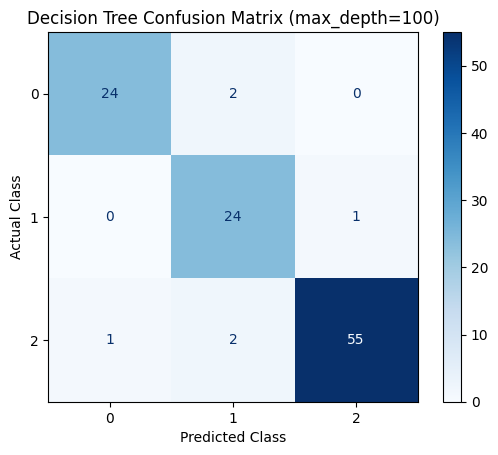

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm100,
    display_labels=[0, 1, 2]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Decision Tree Confusion Matrix (max_depth=100)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()
